
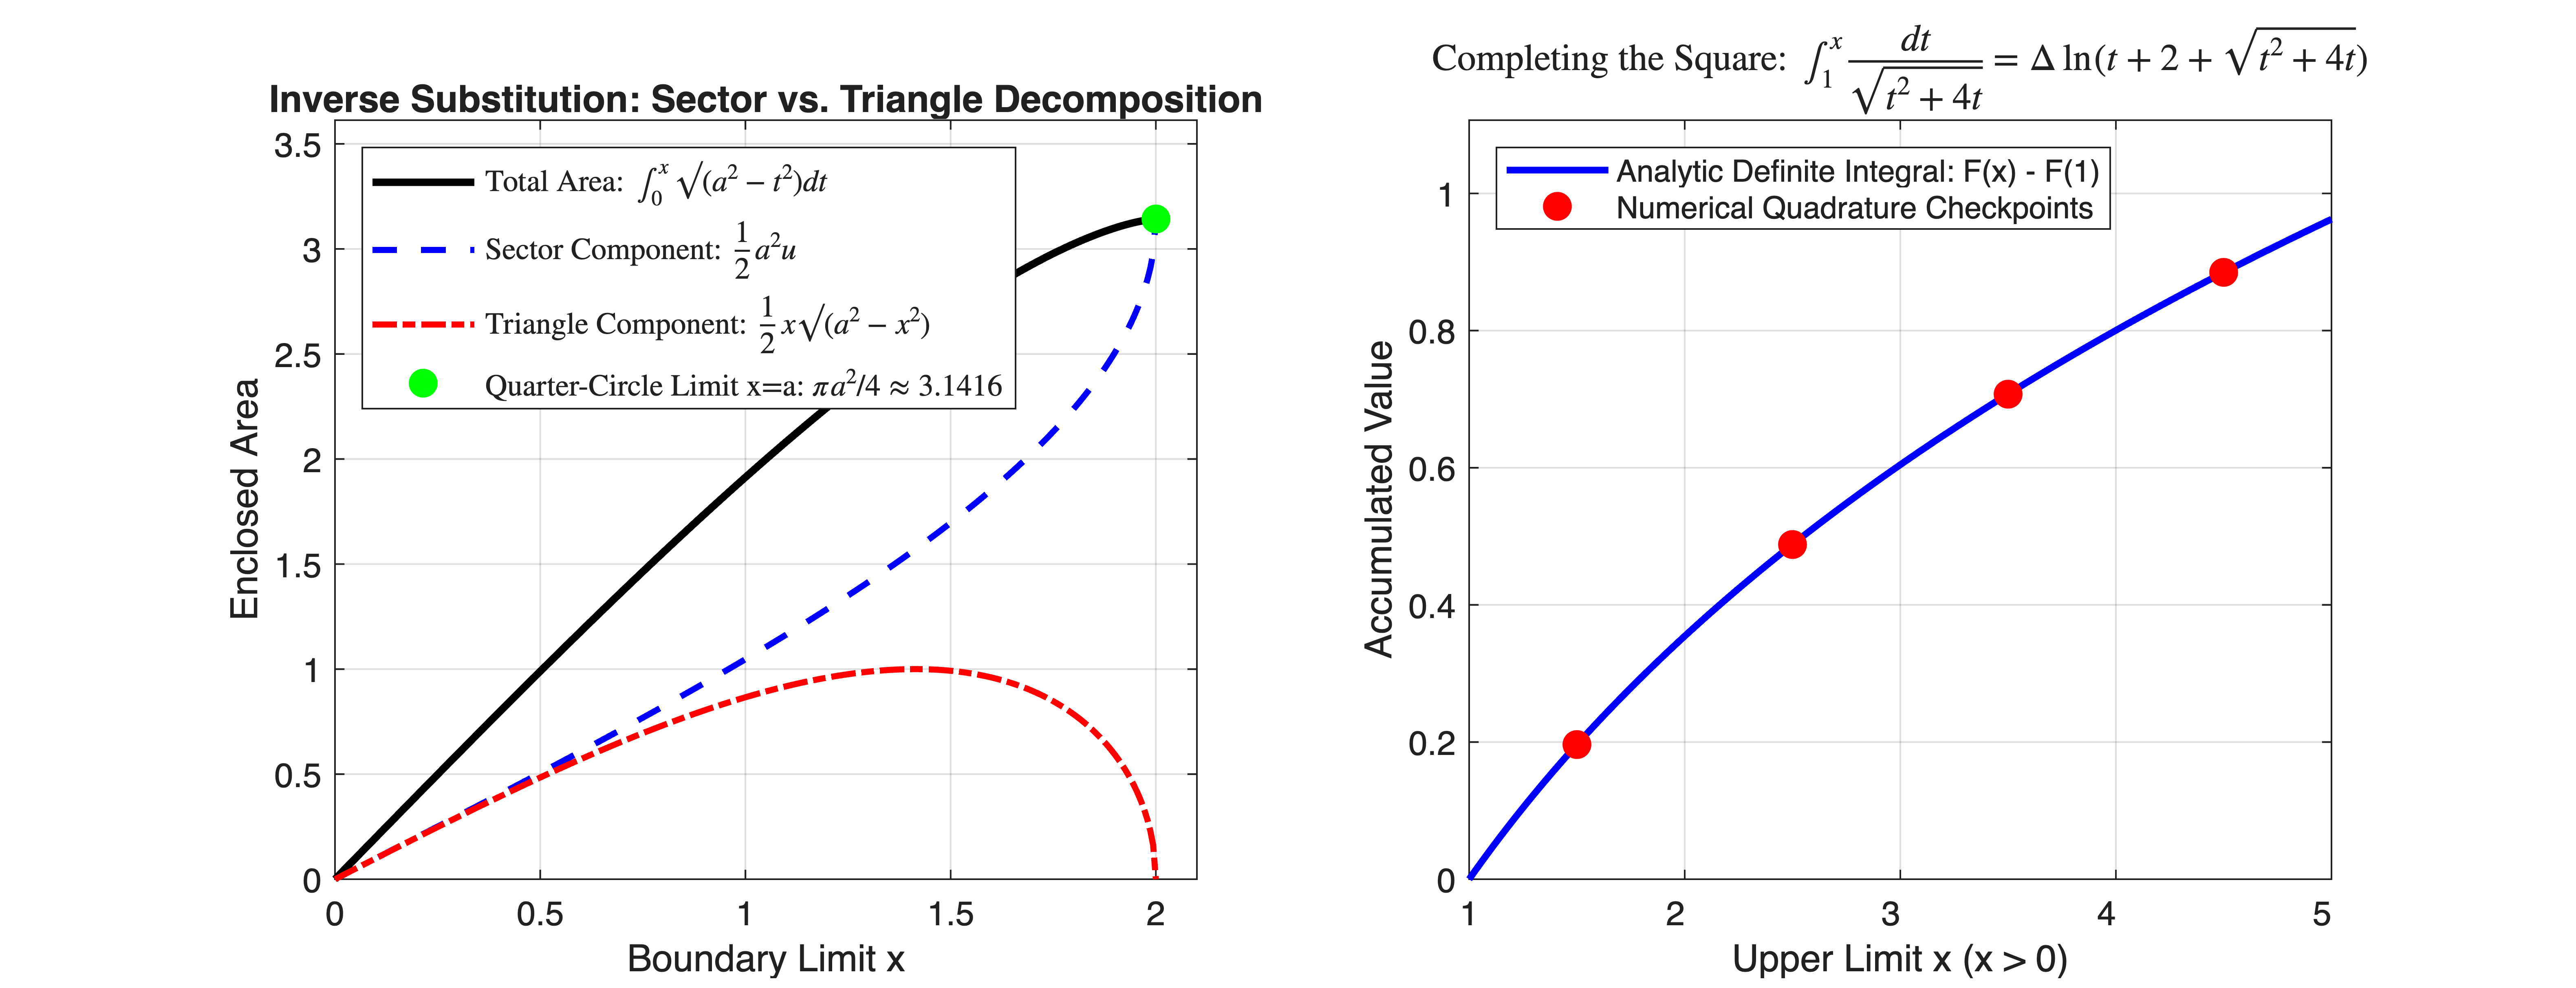

In [1]:
%% MIT 18.01 Lecture 28: Inverse Substitution & Completing the Square Simulation
% Mathematical Tool Application: Used for matrix completing the square in LQR/HJB optimal control,
% radical elimination in manipulator inverse kinematics, and capsule geometry volume evaluation.


clear; clc; close all;


%% Part 1: Semicircle Area Geometric Decomposition (t = a*sin(u))
% Semicircle radius a = 2.0. Integral: \int_0^x sqrt(a^2 - t^2) dt
a_rad = 2.0;
x_domain = linspace(0.0, a_rad, 300);


% Geometric Component 1: Circular Sector Area = 0.5 * a^2 * asin(x / a)
sector_area = 0.5 * (a_rad^2) * asin(x_domain ./ a_rad);


% Geometric Component 2: Triangle Area = 0.5 * x * sqrt(a^2 - x^2)
triangle_area = 0.5 * x_domain .* sqrt(max(0, a_rad^2 - x_domain.^2));


% Total Analytic Area derived in Lecture 28
total_analytic_area = sector_area + triangle_area;


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_domain, total_analytic_area, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Total Area: $\int_0^x \surd(a^2-t^2)dt$'); hold on;
plot(x_domain, sector_area, 'b--', 'LineWidth', 1.8, 'DisplayName', 'Sector Component: $\frac{1}{2}a^2 u$');
plot(x_domain, triangle_area, 'r-.', 'LineWidth', 1.8, 'DisplayName', 'Triangle Component: $\frac{1}{2}x\surd(a^2-x^2)$');


% Highlight full quarter-circle limit at x = a (Triangle = 0, Sector = pi*a^2/4)
quarter_circle_area = (pi * a_rad^2) / 4.0;
plot(a_rad, quarter_circle_area, 'go', 'MarkerSize', 8, 'MarkerFaceColor', 'g', ...
    'DisplayName', sprintf('Quarter-Circle Limit x=a: $\\pi a^2/4 \\approx %.4f$', quarter_circle_area));


grid on;
xlim([0, a_rad + 0.1]); ylim([0, quarter_circle_area * 1.15]);
xlabel('Boundary Limit x');
ylabel('Enclosed Area');
title('Inverse Substitution: Sector vs. Triangle Decomposition');
legend('Location', 'northwest','Interpreter', 'latex');


%% Part 2: Completing the Square Integral: \int 1 / sqrt(x^2 + 4x) dx
% Problem: \int 1 / sqrt((x+2)^2 - 4) dx ==> v = x + 2, v = 2*sec(u)
% Analytic Antiderivative: F(x) = ln(x + 2 + sqrt(x^2 + 4x))
F_analytic = @(x) log(x + 2.0 + sqrt(x.^2 + 4.0 * x));
f_kernel   = @(x) 1.0 ./ sqrt(x.^2 + 4.0 * x);


% Integration limits on real valid domain (x > 0)
x_lower = 1.0;
x_eval_span = linspace(1.0, 5.0, 200);


% Definite Integral: I(x) = F(x) - F(x_lower)
analytic_definite = F_analytic(x_eval_span) - F_analytic(x_lower);


% Numerical verification via adaptive quadrature at discrete checkpoints
checkpoints = [1.5, 2.5, 3.5, 4.5];
num_checkpoints = zeros(size(checkpoints));
for k = 1:length(checkpoints)
    num_checkpoints(k) = integral(f_kernel, x_lower, checkpoints(k), 'RelTol', 1e-12, 'AbsTol', 1e-14);
end


subplot(1, 2, 2);
plot(x_eval_span, analytic_definite, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 'Analytic Definite Integral: F(x) - F(1)'); hold on;
plot(checkpoints, num_checkpoints, 'ro', 'MarkerSize', 8, 'MarkerFaceColor', 'r', ...
    'DisplayName', 'Numerical Quadrature Checkpoints');


grid on;
xlim([1.0, 5.0]); ylim([0, max(analytic_definite) * 1.15]);
xlabel('Upper Limit x (x > 0)');
ylabel('Accumulated Value');
title('Completing the Square: $\int_1^x \frac{dt}{\sqrt{t^2 + 4t}} = \Delta \ln(t+2+\sqrt{t^2+4t})$', ...
      'Interpreter', 'latex');
legend('Location', 'northwest');